In [ ]:
!pip install pyxlsb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [ ]:
# 1. 데이터 로드 (.xlsb 파일 읽기)
# xlsb 파일을 읽으려면 'pyxlsb' 라이브러리가 필요할 수 있습니다.
# 코랩에서 에러가 나면 !pip install pyxlsb 를 코드 맨 위에 넣어주세요.

file_name = '2025년 세종 한누리대로 VDS15분교통량(지점_총량) 정리.xlsb'

try:
    # 엑셀 파일(.xlsb)을 읽어오는 함수로 변경
    df = pd.read_excel(file_name, engine='pyxlsb')
    print("파일 로드 성공!")
except Exception as e:
    print(f"파일 로드 실패: {e}")
    print("파일명이 정확한지, 코랩 왼쪽 폴더에 파일을 업로드했는지 확인해주세요.")

파일 로드 성공!


In [ ]:
# 2-1. 시계열 정렬 및 인덱스 설정
# 승준 님이 엑셀에서 만든 '열1' 컬럼을 기준으로 정렬합니다.
df['열1'] = pd.to_datetime(df['열1'])
df = df.sort_values(by='열1').reset_index(drop=True)

# 전처리 단계에 추가하면 성능이 확 올라가는 코드
df['yesterday_speed'] = df['값.1'].shift(96)          # 어제 이 시간 속도
df['last_week_speed'] = df['값.1'].shift(96 * 7)      # 지난주 이 시간 속도

# 2-2. 파생 변수(요일, 시간, 주말여부) 생성
df['요일'] = df['열1'].dt.dayofweek  # 월:0 ~ 일:6
df['시간'] = df['열1'].dt.hour       # 0~23시
df['주말여부'] = df['요일'].apply(lambda x: 1 if x >= 5 else 0) # 토, 일은 1

# 2-3. 분석 변수 선택
# 값(교통량), 값.1(평균속도), 신호주기 + 요일 특성들
features = ['값', '값.1', '신호주기', '요일', '주말여부', '시간', 'yesterday_speed', 'last_week_speed']
df_final = df[features].copy()

# 2-4. 비정상 데이터('-' 등) 숫자 변환 및 결측치 처리
# 문자열이 섞여 있으면 학습이 안 되므로 모두 숫자로 강제 변환합니다.
for col in features:
    df_final[col] = pd.to_numeric(df_final[col], errors='coerce')

# 변환 중 생긴 NaN(결측치)을 0으로 채웁니다. (교통 데이터 특성 반영)
df_final = df_final.fillna(0)

# 2-5. 데이터 정규화 (MinMaxScaler)
# 모든 데이터를 0~1 사이 값으로 맞춰주어 LSTM 학습 효율을 높입니다.
scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(df_final)

print("✅ 데이터 전처리가 완료되었습니다!")
print(f"최종 분석 변수: {features}")
print(f"데이터 형상: {df_scaled.shape}")


✅ 데이터 전처리가 완료되었습니다!
최종 분석 변수: ['값', '값.1', '신호주기', '요일', '주말여부', '시간', 'yesterday_speed', 'last_week_speed']
데이터 형상: (31508, 8)


In [ ]:
# 3. 시계열 데이터 생성 (15분 단위 최적화)
# look_back=8 : 과거 2시간(15분 * 8개)의 데이터를 보고 다음 15분 뒤의 속도를 예측
def create_dataset(data, look_back=8):
    X, y = [], []
    for i in range(len(data) - look_back):
        X.append(data[i:(i + look_back), :])
        # '평균속도'는 features 리스트의 1번 인덱스에 있음
        y.append(data[i + look_back, 1])
    return np.array(X), np.array(y)

look_back = 8
X, y = create_dataset(df_scaled, look_back)

# 학습(80%)과 테스트(20%) 분리
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

In [ ]:
# 4. LSTM 모델 설계 (데이터량 증가에 따른 레이어 강화)
model = Sequential([
    LSTM(64, activation='relu', input_shape=(X.shape[1], X.shape[2]), return_sequences=True),
    Dropout(0.2),
    LSTM(32, activation='relu'),
    Dropout(0.2),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')
print("⏳ 모델 학습을 시작합니다... (데이터량에 따라 시간이 걸릴 수 있습니다)")

⏳ 모델 학습을 시작합니다... (데이터량에 따라 시간이 걸릴 수 있습니다)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
# 5. 모델 학습 (Epochs 증가)
# 데이터가 많아졌으므로 더 많이 학습시킵니다.
history = model.fit(X_train, y_train, epochs=50, batch_size=32,
                    validation_split=0.1, verbose=1)

Epoch 1/50
709/709 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - loss: 0.0160 - val_loss: 0.0048
Epoch 2/50
709/709 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0081 - val_loss: 0.0042
Epoch 3/50
709/709 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0066 - val_loss: 0.0040
Epoch 4/50
709/709 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0059 - val_loss: 0.0040
Epoch 5/50
709/709 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0054 - val_loss: 0.0039
Epoch 6/50
709/709 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0052 - val_loss: 0.0040
Epoch 7/50
709/709 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0051 - val_loss: 0.0039
Epoch 8/50
709/709 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0051 - val_loss: 0.0038
Epoch 9/50
709/709 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0051 - val_loss: 0.0038
Epoch 10/50
709/709 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0050 - val_loss: 0.0038
Epoch 11/50
709/709 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0050 - val_loss: 0.0039
Epoch 12/50
709/709 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/st

📊 현재 시각화 가능한 데이터는 총 65일분입니다.


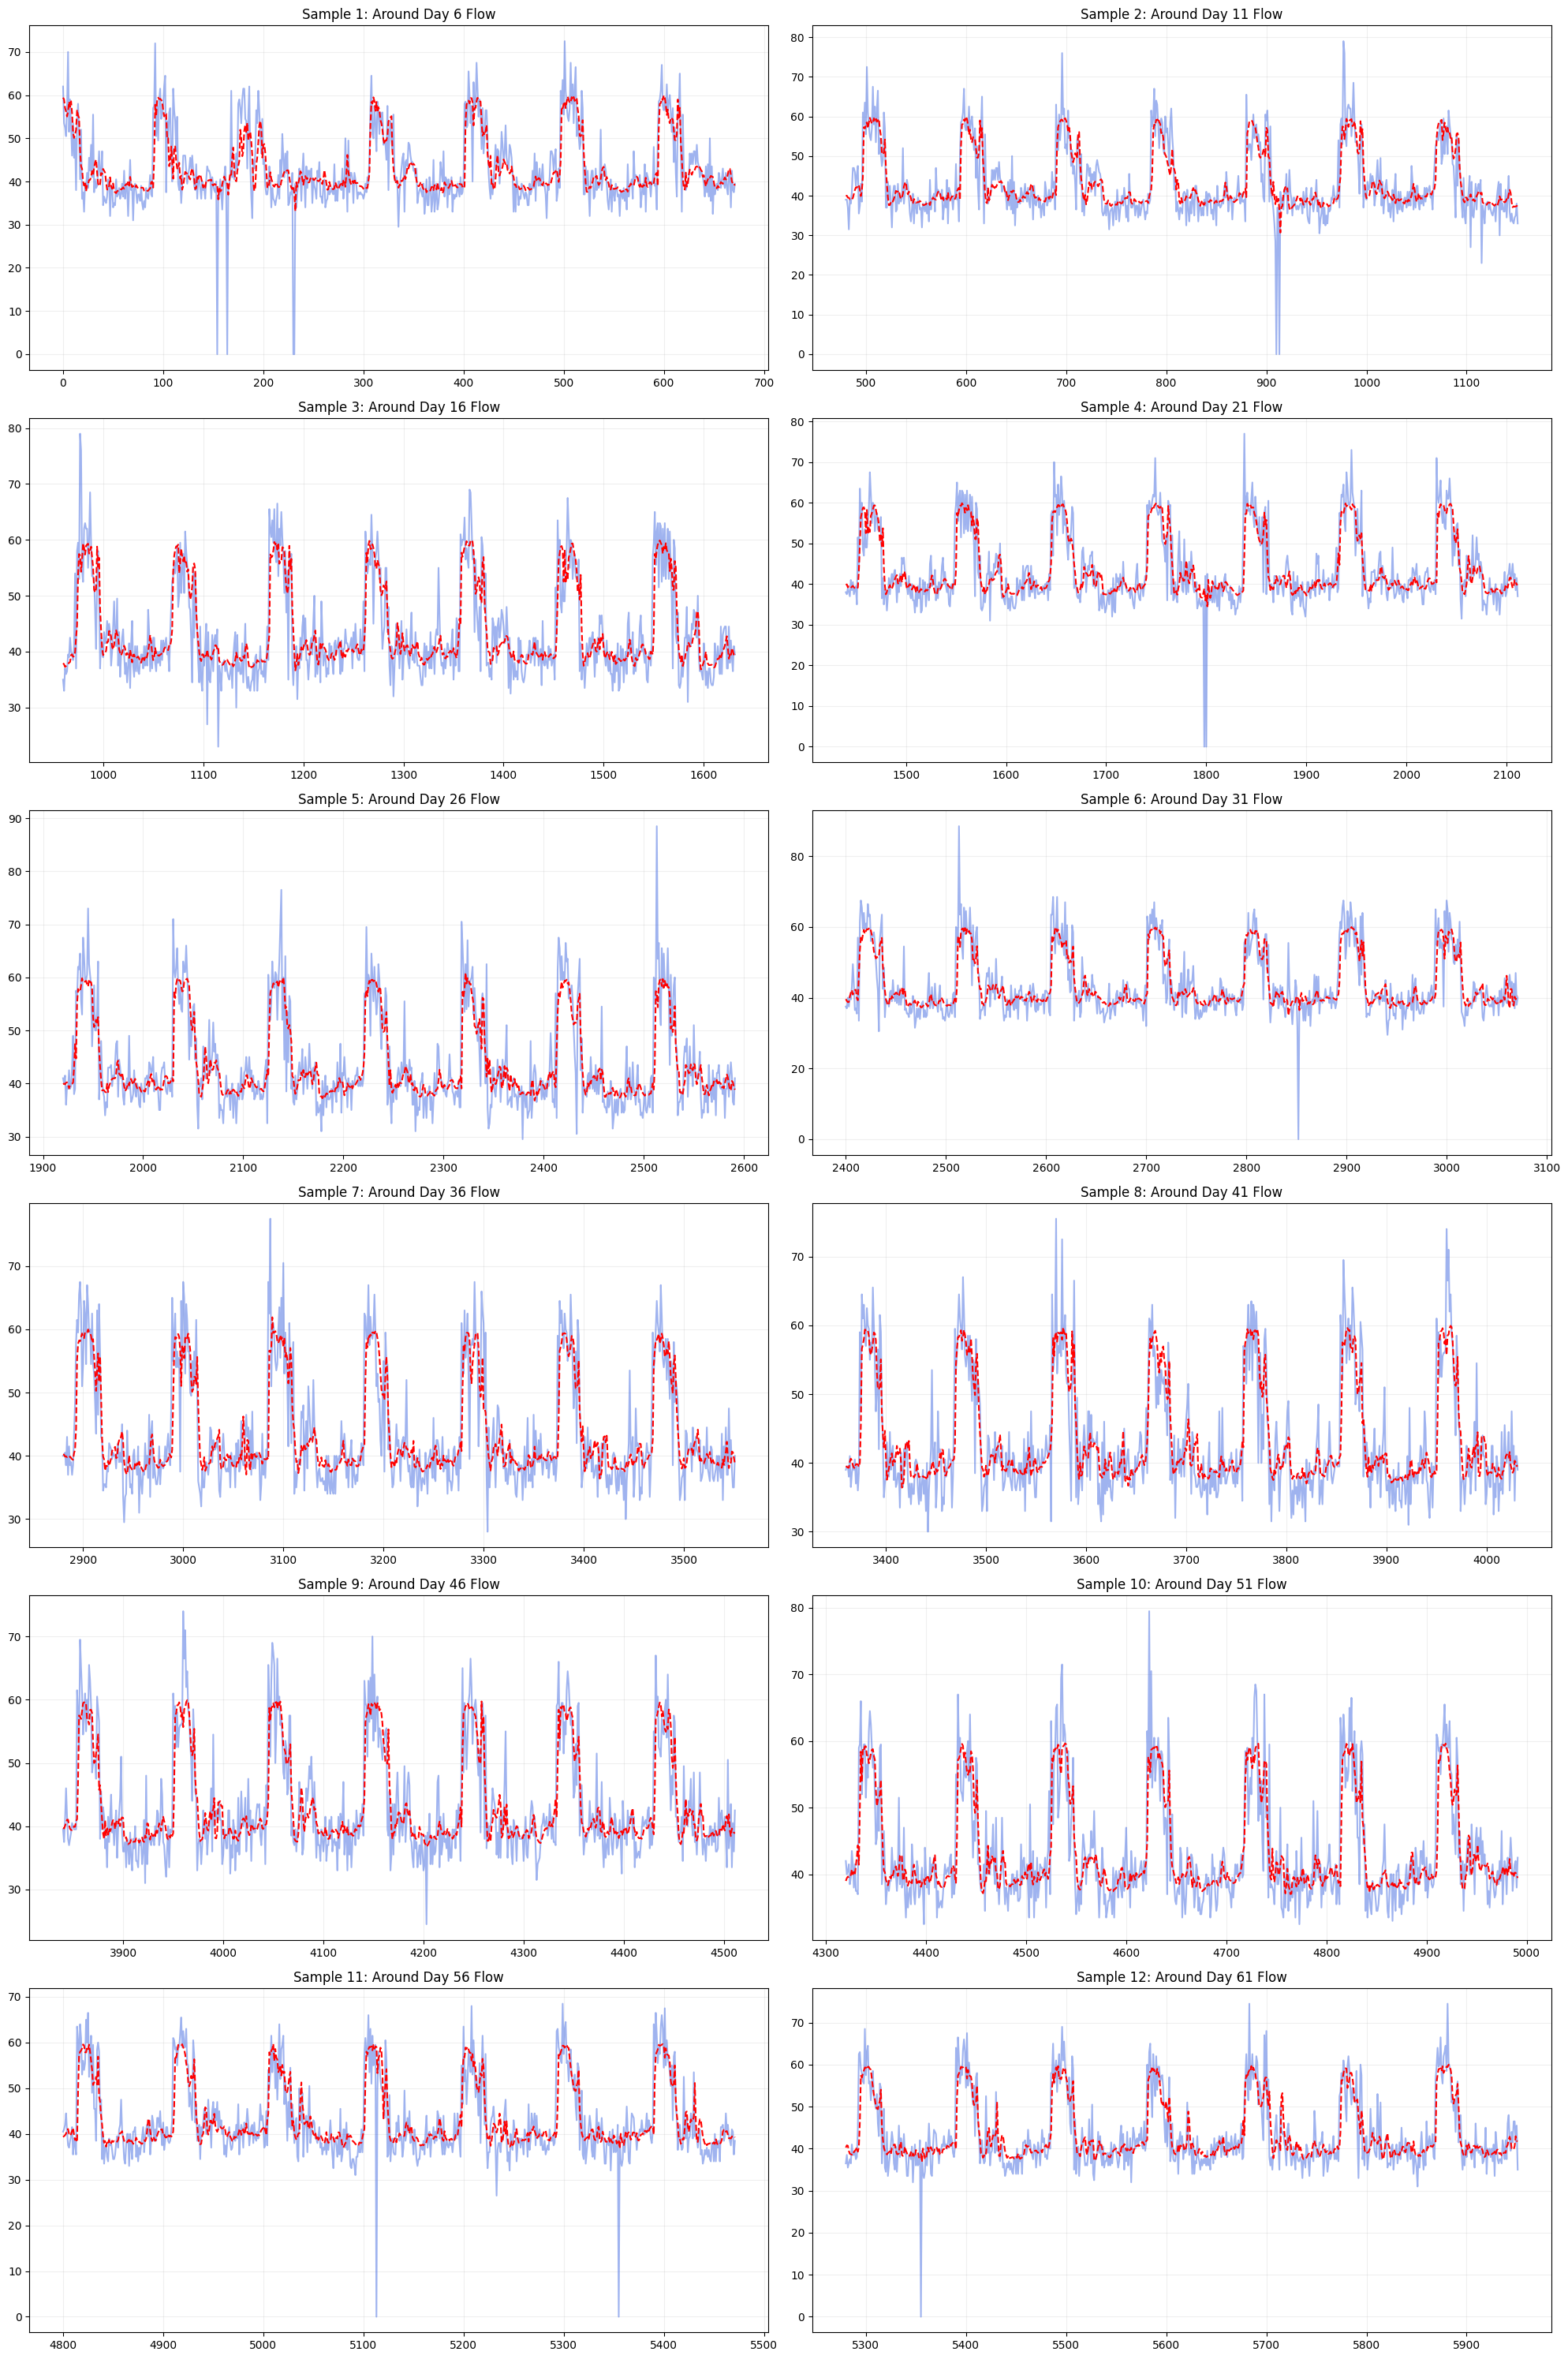

In [ ]:
import math

# 1. 테스트 데이터에 며칠 분량이 있는지 계산
total_days = len(plot_df) // 96
print(f"📊 현재 시각화 가능한 데이터는 총 {total_days}일분입니다.")

# 2. 며칠 간격으로 샘플을 뽑을지 결정 (최대 12개 그래프)
# 데이터가 적으면 3일 간격, 많으면 30일 간격으로 자동 조절
step_days = max(1, total_days // 12)

# 3. 그래프 그리기
num_plots = min(12, total_days // step_days)
cols = 2
rows = math.ceil(num_plots / cols)

fig, axes = plt.subplots(rows, cols, figsize=(20, 5 * rows))
axes = axes.flatten()

for i in range(num_plots):
    start_idx = i * step_days * 96
    end_idx = start_idx + (96 * 7) # 일주일치

    if end_idx <= len(plot_df):
        sample_data = plot_df.iloc[start_idx:end_idx]
        ax = axes[i]

        ax.plot(sample_data['index'], sample_data['실제값'], color='royalblue', alpha=0.5)
        ax.plot(sample_data['index'], sample_data['예측값'], color='red', linestyle='--')

        # 시작 지점의 대략적인 날짜 계산 (기존 1월 6일 기준)
        current_day = (start_idx // 96) + 6
        ax.set_title(f'Sample {i+1}: Around Day {current_day} Flow', fontsize=12)
        ax.grid(True, alpha=0.2)
    else:
        axes[i].axis('off') # 데이터 없으면 숨김

plt.tight_layout()
plt.show()

In [ ]:
# KPI 지표
rmse = np.sqrt(mean_squared_error(y_test_unscaled, y_pred_unscaled))
print(f"✅ 15분 단위 모델 RMSE: {rmse:.2f} km/h")

✅ 15분 단위 모델 RMSE: 5.18 km/h


In [ ]:
# 6-3. KPI 성능 지표 출력 (RMSE, MAE)
rmse = np.sqrt(mean_squared_error(y_test_unscaled, y_pred_unscaled))
mae = mean_absolute_error(y_test_unscaled, y_pred_unscaled)
print(f"✅ 모델 성능 지표 (KPI):")
print(f"- RMSE (Root Mean Squared Error): {rmse:.2f} km/h")
print(f"- MAE (Mean Absolute Error): {mae:.2f} km/h")

✅ 모델 성능 지표 (KPI):
- RMSE (Root Mean Squared Error): 5.18 km/h
- MAE (Mean Absolute Error): 3.60 km/h
